# Liver EDA – Indian Liver Patient Dataset (ILPD)
Schema validation, missingness, class balance, distributions and correlations. Label `Dataset`: 1 = record from a liver patient, 2 = non-patient (dataset authors' definition, not a diagnosis).

In [1]:
import sys, os
sys.path.insert(0, os.path.abspath('..'))
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
pd.set_option('display.width', 140)
from ml.liver.data import load_ilpd, validate_ilpd
df = load_ilpd('../datasets/liver/indian_liver_patient.csv')
df.head()

,Age,Gender,Total_Bilirubin,Direct_Bilirubin,Alkaline_Phosphotase,Alamine_Aminotransferase,Aspartate_Aminotransferase,Total_Protiens,Albumin,Albumin_and_Globulin_Ratio,Dataset
0,65,Female,0.7,0.1,187.0,16,18.0,6.8,3.3,0.90,1
1,62,Male,10.9,5.5,699.0,64,100.0,7.5,3.2,0.74,1
2,62,Male,7.3,4.1,490.0,60,68.0,7.0,3.3,0.89,1
3,58,Male,1.0,0.4,182.0,14,20.0,6.8,3.4,1.00,1
4,72,Male,3.9,2.0,195.0,27,59.0,7.3,2.4,0.40,1


In [2]:
rep = validate_ilpd(df); rep.as_dict()

{'n_rows': 583,
 'n_columns': 11,
 'missing': {'Albumin_and_Globulin_Ratio': 4},
 'out_of_range': {},
 'exact_duplicates': 13,
 'class_counts': {'1': 416, '2': 167},
 'gender_counts': {'Male': 441, 'Female': 142},
 'issues': ['3 rows with direct bilirubin > total bilirubin']}

In [3]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
Age,583.0,44.746141,16.189833,4.0,33.0,45.00,58.0,90.0
Total_Bilirubin,583.0,3.298799,6.209522,0.4,0.8,1.00,2.6,75.0
Direct_Bilirubin,583.0,1.486106,2.808498,0.1,0.2,0.30,1.3,19.7
Alkaline_Phosphotase,583.0,290.576329,242.937989,63.0,175.5,208.00,298.0,2110.0
Alamine_Aminotransferase,583.0,80.713551,182.620356,10.0,23.0,35.00,60.5,2000.0
Aspartate_Aminotransferase,583.0,109.910806,288.918529,10.0,25.0,42.00,87.0,4929.0
Total_Protiens,583.0,6.483190,1.085451,2.7,5.8,6.60,7.2,9.6
Albumin,583.0,3.141852,0.795519,0.9,2.6,3.10,3.8,5.5
Albumin_and_Globulin_Ratio,579.0,0.947064,0.319592,0.3,0.7,0.93,1.1,2.8
Dataset,583.0,1.286449,0.452490,1.0,1.0,1.00,2.0,2.0


In [4]:
df['Dataset'].value_counts().rename({1:'liver patient',2:'non-patient'})

Dataset
liver patient    416
non-patient      167
Name: count, dtype: int64

## Skewed enzyme distributions (log scale)

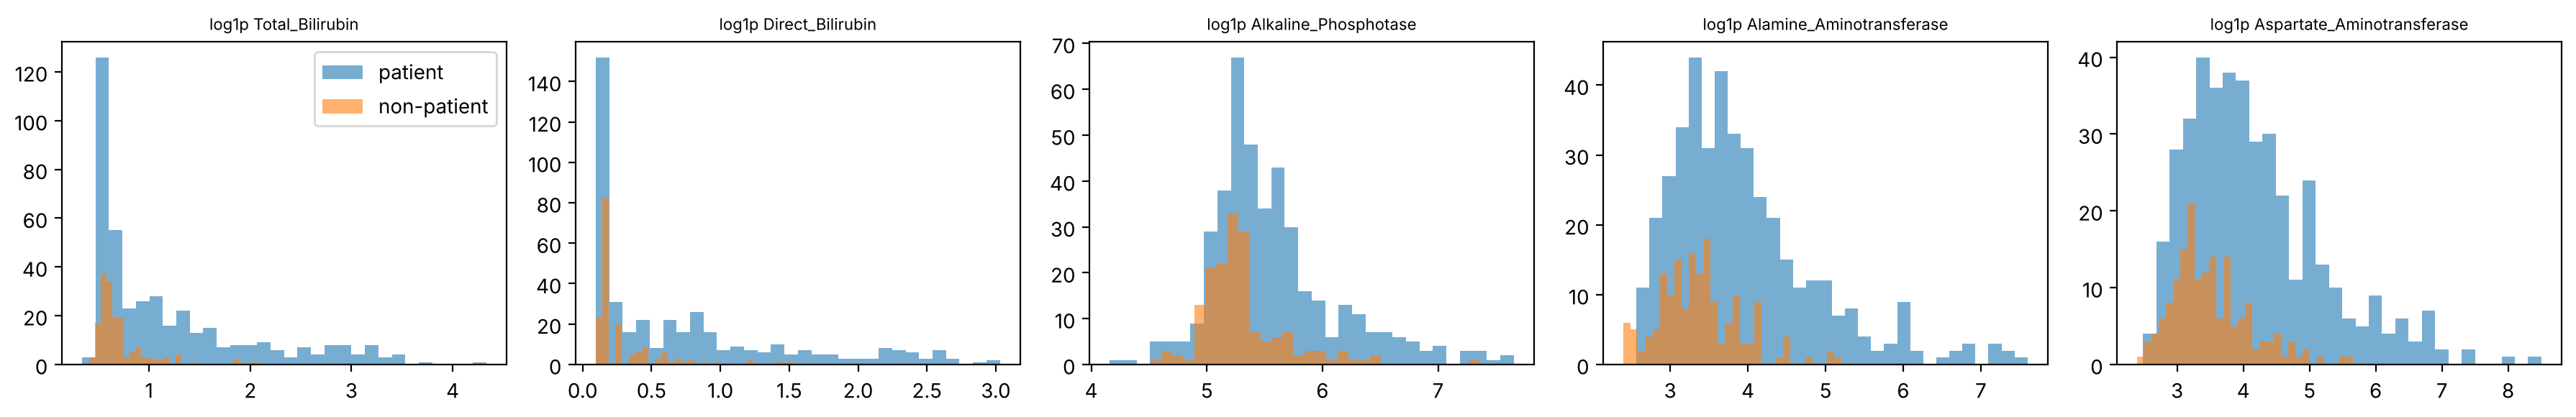

In [5]:
cols=['Total_Bilirubin','Direct_Bilirubin','Alkaline_Phosphotase','Alamine_Aminotransferase','Aspartate_Aminotransferase']
fig,ax=plt.subplots(1,5,figsize=(18,3))
for a,c in zip(ax,cols):
    for lab,g in df.groupby('Dataset'): a.hist(np.log1p(g[c]),bins=30,alpha=.6,label={1:'patient',2:'non-patient'}[lab])
    a.set_title('log1p '+c,fontsize=8)
ax[0].legend(); plt.tight_layout()

In [6]:
df.drop(columns=['Gender']).corr(method='spearman').round(2)

,Age,Total_Bilirubin,Direct_Bilirubin,Alkaline_Phosphotase,Alamine_Aminotransferase,Aspartate_Aminotransferase,Total_Protiens,Albumin,Albumin_and_Globulin_Ratio,Dataset
Age,1.00,0.11,0.11,0.06,-0.07,-0.02,-0.17,-0.26,-0.25,-0.13
Total_Bilirubin,0.11,1.00,0.96,0.38,0.44,0.51,-0.02,-0.22,-0.29,-0.30
Direct_Bilirubin,0.11,0.96,1.00,0.37,0.41,0.50,-0.02,-0.23,-0.30,-0.30
Alkaline_Phosphotase,0.06,0.38,0.37,1.00,0.41,0.40,0.01,-0.17,-0.32,-0.27
Alamine_Aminotransferase,-0.07,0.44,0.41,0.41,1.00,0.77,-0.02,-0.05,-0.08,-0.29
Aspartate_Aminotransferase,-0.02,0.51,0.50,0.40,0.77,1.00,-0.08,-0.20,-0.21,-0.31
Total_Protiens,-0.17,-0.02,-0.02,0.01,-0.02,-0.08,1.00,0.78,0.27,0.03
Albumin,-0.26,-0.22,-0.23,-0.17,-0.05,-0.20,0.78,1.00,0.75,0.17
Albumin_and_Globulin_Ratio,-0.25,-0.29,-0.30,-0.32,-0.08,-0.21,0.27,0.75,1.00,0.19
Dataset,-0.13,-0.30,-0.30,-0.27,-0.29,-0.31,0.03,0.17,0.19,1.00


Observations: strong right skew in bilirubin and enzymes (log transform used for logistic regression); TB/DB and ALT/AST are highly correlated; 4 missing A/G ratios; 13 exact duplicate rows (removed before splitting to avoid leakage); 3 rows with direct > total bilirubin (kept, flagged).